# Spotify DJ playlist


This project started from a conversation with a friend who had recently taken up DJing. While playing around with her decks, she mentioned how difficult it is to build a playlist from scratch - not knowing which songs to use or in what order. I shared that song selection had been my biggest challenge too when I tried DJing. Although software like Rekordbox helps by suggesting similar tracks based on BPM and key, constructing a set from scratch is still surprisingly hard.

That got me thinking more deeply about how music sets are structured. I remembered attending a symphonic orchestra concert, where the conductor spoke openly about how he had curated the evening's programme. It struck me how similarly well-crafted DJ sets need to be, starting at a slower tempo, gradually building excitement, reaching a peak, and then either sustaining that energy or winding back down toward the end. That became the inspiration for this project: making it easier for someone new to start DJing abd building their own set. 

## Let's set it up!

In [1]:
#Install library 
!pip3 install spotipy

In [2]:
#import everything that we need 

import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import requests
import time

In [3]:
# Spotify credentials are read from environment variables, so they are never stored in the notebook.
# Set SPOTIPY_CLIENT_ID and SPOTIPY_CLIENT_SECRET on your computer before running.
import os
SPOTIPY_CLIENT_ID = os.environ['SPOTIPY_CLIENT_ID']
SPOTIPY_CLIENT_SECRET = os.environ['SPOTIPY_CLIENT_SECRET']


In [4]:
#First we authenticate 
import spotipy
from spotipy.oauth2 import SpotifyClientCredentials

auth_manager = SpotifyClientCredentials(SPOTIPY_CLIENT_ID,SPOTIPY_CLIENT_SECRET)
sp = spotipy.Spotify(auth_manager=auth_manager)

## First lesson I learnt - how to choose a playlist

For the first attempt I tried out a playlist that was created by Spotify with Top most requested DJ songs in 2026. I analysed the songs and their features, and it turned out that all songs were way too similiar to each other, and there wasn't enough variation to build a meaningful set. Then I asked my friend who I mentioned above to share with me a playlist she uses. 

## Let's code this playlist!

In [5]:
playlist_id = '262fctoOEv1GelmarGQcgw'

In [6]:
limit = 300 
trim = True

In [7]:
base_url = "https://api.reccobeats.com/v1/track"
track_id = "262fctoOEv1GelmarGQcgw"
try:
    url = f"{base_url}?ids={track_id}"
    response = requests.get(url)
    if response.status_code == 200:
        print(response.json())
    else:
        print(f"Error fetching features for {track_id}: {response.status_code}")
except Exception as e:
    print(f"Exception fetching features for {track_id}: {e}")


{'content': []}


In [8]:
#Get playlist
playlist = sp.playlist(playlist_id)
#Extract tracks
tracks = playlist["tracks"]["items"]
if trim:
    tracks = tracks[-limit:]
#Extract track IDs
ids = [track["track"]["id"] for track in tracks]

In [9]:
base_url = "https://api.reccobeats.com/v1/track"
track_id = "5v9W09kCOTFh2tEmc6X1iN"
try:
    url = f"{base_url}?ids={track_id}"
    response = requests.get(url)
    if response.status_code == 200:
        print(response.json())
    else:
        print(f"Error fetching features for {track_id}: {response.status_code}")
except Exception as e:
    print(f"Exception fetching features for {track_id}: {e}")

{'content': [{'id': '56070f26-359a-4985-b8cd-fe127ede88fe', 'trackTitle': 'My Old Pals', 'artists': [{'id': '6302e5bc-1453-4ce7-8cee-e78d5d8914ba', 'name': 'Kim Carnes', 'href': 'https://open.spotify.com/artist/5PN2aHIvLEM98XIorsPMhE'}], 'durationMs': 197666, 'isrc': 'USCA28100142', 'ean': None, 'upc': None, 'href': 'https://open.spotify.com/track/5v9W09kCOTFh2tEmc6X1iN', 'availableCountries': 'AR,AU,AT,BE,BO,BR,BG,CA,CL,CO,CR,CY,CZ,DK,DO,DE,EC,EE,SV,FI,FR,GR,GT,HN,HK,HU,IS,IE,IT,LV,LT,LU,MY,MT,MX,NL,NZ,NI,NO,PA,PY,PE,PH,PL,PT,SG,SK,ES,SE,CH,TW,TR,UY,US,GB,AD,LI,MC,ID,JP,TH,VN,RO,IL,ZA,SA,AE,BH,QA,OM,KW,EG,MA,DZ,TN,LB,JO,PS,IN,BY,KZ,MD,UA,AL,BA,HR,ME,MK,RS,SI,KR,BD,PK,LK,GH,KE,NG,TZ,UG,AG,AM,BS,BB,BZ,BT,BW,BF,CV,CW,DM,FJ,GM,GE,GD,GW,GY,HT,JM,KI,LS,LR,MW,MV,ML,MH,FM,NA,NR,NE,PW,PG,WS,SM,ST,SN,SC,SL,SB,KN,LC,VC,SR,TL,TO,TT,TV,VU,AZ,BN,BI,KH,CM,TD,KM,GQ,SZ,GA,GN,KG,LA,MO,MR,MN,NP,RW,TG,UZ,ZW,BJ,MG,MU,MZ,AO,CI,DJ,ZM,CD,CG,IQ,LY,TJ,VE,ET,XK', 'popularity': 15}]}


In [10]:
#There wont always be an exact match!
base_url = "https://api.reccobeats.com/v1/track"
def get_reccobeats_id(track_id):
    try:
        url = f"{base_url}?ids={track_id}"
        response = requests.get(url)
        if response.status_code == 200 and len(response.json()["content"])>0:
            data = response.json()["content"][0]
            name = data["trackTitle"] + " - " + data["artists"][0]["name"]
            recco_id = data["id"]
            print(f"success fetching {name}")
            return [name,recco_id]
        else:
            print(f"Error fetching id for {track_id}: {response.status_code}")
            return None
    except Exception as e:
        print(f"Exception fetching id for {track_id}: {e}")
        return None
recco_ids = []
for track_id in ids:
    features_data = get_reccobeats_id(track_id)
    if features_data:
        recco_ids.append(features_data)
    # Be nice to the API - add a small delay
    time.sleep(0.1)

success fetching Anasickmodular - Floating Points
success fetching Manifest - Coco & Breezy
Error fetching id for 2eZpdadGXG64NU6CEXv3sE: 200
success fetching El Apagón - Bad Bunny
Error fetching id for 6NLWP1Bpt7uaVtRWVzVQZ4: 200
success fetching VOLVER - Tainy
success fetching flight fm - Joy Orbison
success fetching In For The Kill - Skream's Let's Get Ravey Remix - La Roux
success fetching Alive - DJ HEARTSTRING Remix - Empire Of The Sun
success fetching Rain - FISHER
Error fetching id for 3QrcVUaPX6v9eIsz2SyVWV: 200
Error fetching id for 5VYFPf4MuiPTjL4geOkEH3: 200
success fetching Stil - Frankie Lluc Remix - Acid Arab
success fetching So U Kno - Overmono
success fetching Opal - Four Tet Remix - BICEP
success fetching God Is The Space Between Us - Barry Can't Swim
Error fetching id for 2ZG3zaIGpmIFU4CTwhhgyn: 200
success fetching Secrets (feat. RHODES) - Sub Focus
success fetching Gunk - Overmono
success fetching Glue - BICEP
success fetching Apricots - BICEP
success fetching Hyph

In [11]:
#Check how many matches we were able to make
len(recco_ids)

34

Only 34 out of 40 songs were fetched using the Reccobeats API. 

In [12]:
# Get audio features from ReccoBeats API (replaces sp.audio_features())
# ReccoBeats is free and doesn't require authentication
base_url = "https://api.reccobeats.com/v1"

def get_audio_features_reccobeats(track_id):
    """Get audio features for a single track from ReccoBeats API"""
    try:
        url = f"{base_url}/audio-features?ids={track_id}"
        print(url)
        response = requests.get(url)
        if response.status_code == 200:
            return response.json()
        else:
            print(f"Error fetching features for {track_id}: {response.status_code}")
            return None
    except Exception as e:
        print(f"Exception fetching features for {track_id}: {e}")
        return None

# Fetch audio features for all tracks
audio_features_list = []
labels = []

for track in recco_ids:
    track_id = track[1]
    features_data = get_audio_features_reccobeats(track_id)
    if features_data:
        print(features_data)
        labels.append(track[0])
        features_data = features_data["content"][0]
        features_data.pop('id', None)
        features_data.pop('href', None)
        features_data.pop('isrc', None)
        audio_features_list.append(features_data)
    # Be nice to the API - add a small delay
    time.sleep(0.1)

#Create dataframe from audio features
features = pd.DataFrame(audio_features_list)
#Label dataframe rows with track name and artist
features.index = labels

https://api.reccobeats.com/v1/audio-features?ids=d81e542e-dae2-4acb-a01f-387b4924c6d5
{'content': [{'id': 'd81e542e-dae2-4acb-a01f-387b4924c6d5', 'href': 'https://open.spotify.com/track/78Ct2qlEtSMw3CG6zWwAyz', 'isrc': 'GBCFB1900154', 'acousticness': 0.0154, 'danceability': 0.667, 'energy': 0.567, 'instrumentalness': 0.945, 'key': 1, 'liveness': 0.118, 'loudness': -11.629, 'mode': 1, 'speechiness': 0.044, 'tempo': 139.088, 'valence': 0.338}]}
https://api.reccobeats.com/v1/audio-features?ids=9dcd2003-1ef8-40a9-b588-b14ac602d375
{'content': [{'id': '9dcd2003-1ef8-40a9-b588-b14ac602d375', 'href': 'https://open.spotify.com/track/1NMSZn1gconZXGv0NSRuO6', 'isrc': 'USYBL2400462', 'acousticness': 0.646, 'danceability': 0.77, 'energy': 0.683, 'instrumentalness': 0.00309, 'key': 6, 'liveness': 0.221, 'loudness': -7.848, 'mode': 1, 'speechiness': 0.298, 'tempo': 126.023, 'valence': 0.298}]}
https://api.reccobeats.com/v1/audio-features?ids=257c76c5-fbda-44d7-870b-7b890252c4e8
{'content': [{'id': '

In [13]:
import pandas as pd
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)


# Let's look at my playlist's features

In [14]:
features

,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,valence
Anasickmodular - Floating Points,0.015400,0.667,0.567,0.945000,1,0.1180,-11.629,1,0.0440,139.088,0.3380
Manifest - Coco & Breezy,0.646000,0.770,0.683,0.003090,6,0.2210,-7.848,1,0.2980,126.023,0.2980
El Apagón - Bad Bunny,0.050900,0.629,0.698,0.001660,8,0.0909,-4.485,1,0.3080,117.765,0.5990
VOLVER - Tainy,0.030600,0.745,0.887,0.002240,11,0.2450,-2.750,0,0.0437,155.041,0.7220
flight fm - Joy Orbison,0.005660,0.797,0.626,0.492000,9,0.0922,-7.923,1,0.0455,140.001,0.0815
In For The Kill - Skream's Let's Get Ravey Remix - La Roux,0.003290,0.333,0.591,0.260000,6,0.0557,-5.267,0,0.0445,145.480,0.0543
Alive - DJ HEARTSTRING Remix - Empire Of The Sun,0.004570,0.566,0.847,0.623000,7,0.1380,-7.110,0,0.0385,140.994,0.1110
Rain - FISHER,0.002090,0.719,0.783,0.294000,2,0.0874,-5.836,0,0.2370,130.068,0.5270
Stil - Frankie Lluc Remix - Acid Arab,0.000254,0.749,0.906,0.794000,6,0.1110,-3.813,1,0.0500,119.997,0.7740
So U Kno - Overmono,0.100000,0.820,0.605,0.213000,0,0.0398,-8.357,1,0.0482,129.980,0.5590


# Danceability, energy and tempo

To start I wanted to look at danceability, energy and tempo. Danceability and energy are the two I'm most excited about. They both feel really relevant to what makes a good DJ set. Tempo I mainly wanted to check to make sure the transitions between tracks wouldn't be too jarring, and that the BPM differences aren't too large. I won't focus on tempo for building the actual set though, since that's more traditional and can easily be handled by DJ software anyway. The features I really want to focus on are energy and danceability, they're less obvious choices, but extremely relevant to how a set feels. Some DJs might not naturally think about these when curating a playlist, which is exactly where I think this project could be useful.

In [47]:
my_features = ['danceability', 'energy', 'tempo']
features = features[my_features].copy()
features

,danceability,energy,tempo
Anasickmodular - Floating Points,0.667,0.567,139.088
Manifest - Coco & Breezy,0.770,0.683,126.023
El Apagón - Bad Bunny,0.629,0.698,117.765
VOLVER - Tainy,0.745,0.887,155.041
flight fm - Joy Orbison,0.797,0.626,140.001
In For The Kill - Skream's Let's Get Ravey Remix - La Roux,0.333,0.591,145.480
Alive - DJ HEARTSTRING Remix - Empire Of The Sun,0.566,0.847,140.994
Rain - FISHER,0.719,0.783,130.068
Stil - Frankie Lluc Remix - Acid Arab,0.749,0.906,119.997
So U Kno - Overmono,0.820,0.605,129.980


After playing around with the data for a bit, I noticed the BPM range of this playlist is actually pretty realistic for a real DJ set , most tracks sit between 120 and 140 BPM, which is pretty standard for electronic music. There are two tracks around 75 BPM which look like outliers, but in practice a DJ would likely play those at double time, so they'd fit right in with the rest of the set.

We'll look more into the tempo at a later point in this code. 

# Energy


I want to see the songs sorted by energy. 

In [48]:
sort_by = 'energy'
features.sort_values(by = sort_by, ascending = False)

,danceability,energy,tempo
Secrets (feat. RHODES) - Sub Focus,0.632,0.943,130.012
Gunk - Overmono,0.751,0.941,129.023
Stil - Frankie Lluc Remix - Acid Arab,0.749,0.906,119.997
VOLVER - Tainy,0.745,0.887,155.041
OnlyL - TSHA,0.567,0.884,133.750
Alive - DJ HEARTSTRING Remix - Empire Of The Sun,0.566,0.847,140.994
U - DJ Seinfeld,0.721,0.838,125.999
Liverpool Street In The Rain - Mall Grab,0.669,0.801,130.042
Glue - BICEP,0.853,0.798,129.983
Prayer - Edit - Prospa,0.614,0.796,122.981


Sorted by energy, the range goes from 0.44 to 0.94 which is actually a decent spread! Happy to see there's enough variety here to build something interesting.

# Danceability 

Now sorted by danceability. 

In [49]:
sort_by = 'danceability'
features.sort_values(by = sort_by, ascending = False)

,danceability,energy,tempo
Peach - salute,0.866,0.668,135.009
Glue - BICEP,0.853,0.798,129.983
Opal - Four Tet Remix - BICEP,0.826,0.720,127.011
So U Kno - Overmono,0.820,0.605,129.980
Apricots - BICEP,0.819,0.599,127.986
flight fm - Joy Orbison,0.797,0.626,140.001
Manifest - Coco & Breezy,0.770,0.683,126.023
Utility - Barker,0.761,0.772,139.985
Gosh - Jamie xx,0.752,0.459,139.450
Gunk - Overmono,0.751,0.941,129.023


Sorted by danceability, most tracks sit in the mid to high range, which again makes sense for an electronic playlist. What's interesting is that even the tracks at the bottom of the list (like In For The Kill and the Aphex Twin remix) still have danceability scores above 0.3, so even the least danceable tracks in this set are still pretty danceable!

Let's visualise the danceability and energy of each track in a scatter plot. I want to see at a glance which songs are the most energetic and danceable.

# Danceability and Energy

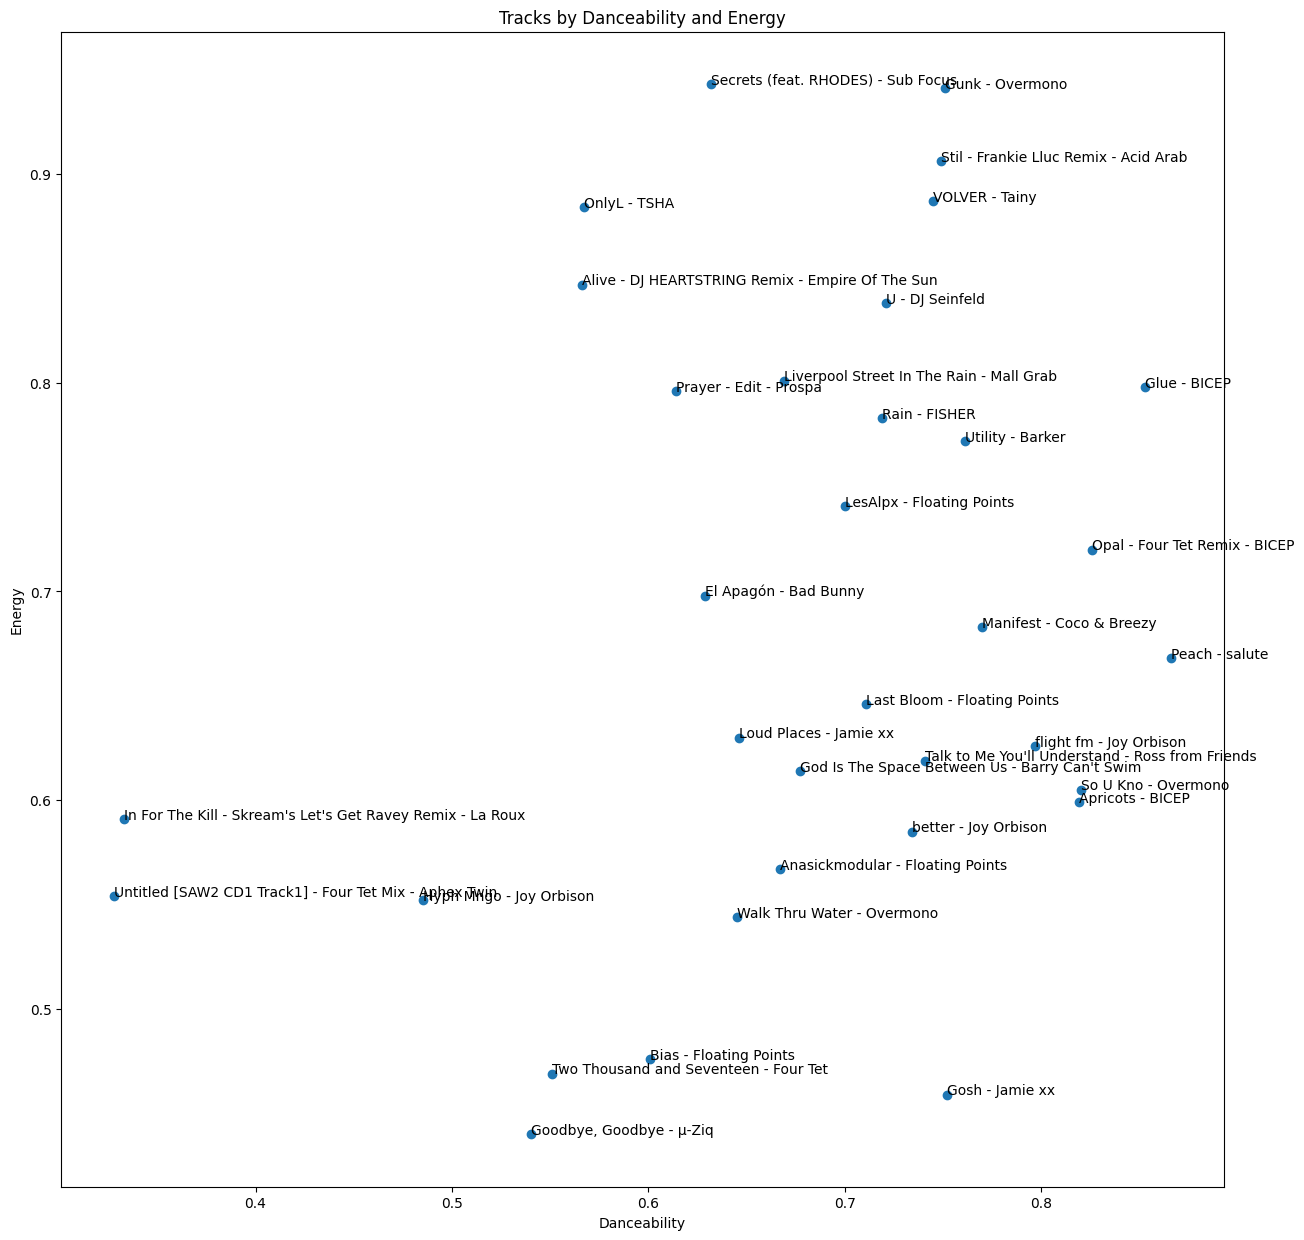

In [78]:
fig, ax = plt.subplots(figsize=(15,15))

x = features['danceability']
y = features['energy']

ax.scatter(x, y)

for i, label in enumerate(features.index):
    ax.annotate(label, (x.iloc[i], y.iloc[i]))

ax.set_xlabel('Danceability')
ax.set_ylabel('Energy')
ax.set_title('Tracks by Danceability and Energy')

plt.show()

# Peak score = Energy + Danceability 

Next I want to create a single score that combines energy and danceability, I'm calling it the peak score. A track can be very energetic but not that danceable, or very danceable but lacking intensity, so combining both gives a better picture of where a track should sit in a set.
I weighted energy slightly higher than danceability (0.6 vs 0.4) since energy feels more important when thinking about the peak moments of a set, while danceability still matters.

In [79]:
features['peak_score'] = (
    0.6 * features['energy'] +
    0.4 * features['danceability']
)


Let's sort the tracks by peak score.

In [80]:
features.sort_values(by='peak_score', ascending=False)[['peak_score']]

,peak_score
Gunk - Overmono,0.8650
Stil - Frankie Lluc Remix - Acid Arab,0.8432
VOLVER - Tainy,0.8302
Glue - BICEP,0.8200
Secrets (feat. RHODES) - Sub Focus,0.8186
U - DJ Seinfeld,0.7912
Utility - Barker,0.7676
Opal - Four Tet Remix - BICEP,0.7624
Rain - FISHER,0.7574
OnlyL - TSHA,0.7572


Viusalising the results in a bar chart. 

<Axes: >

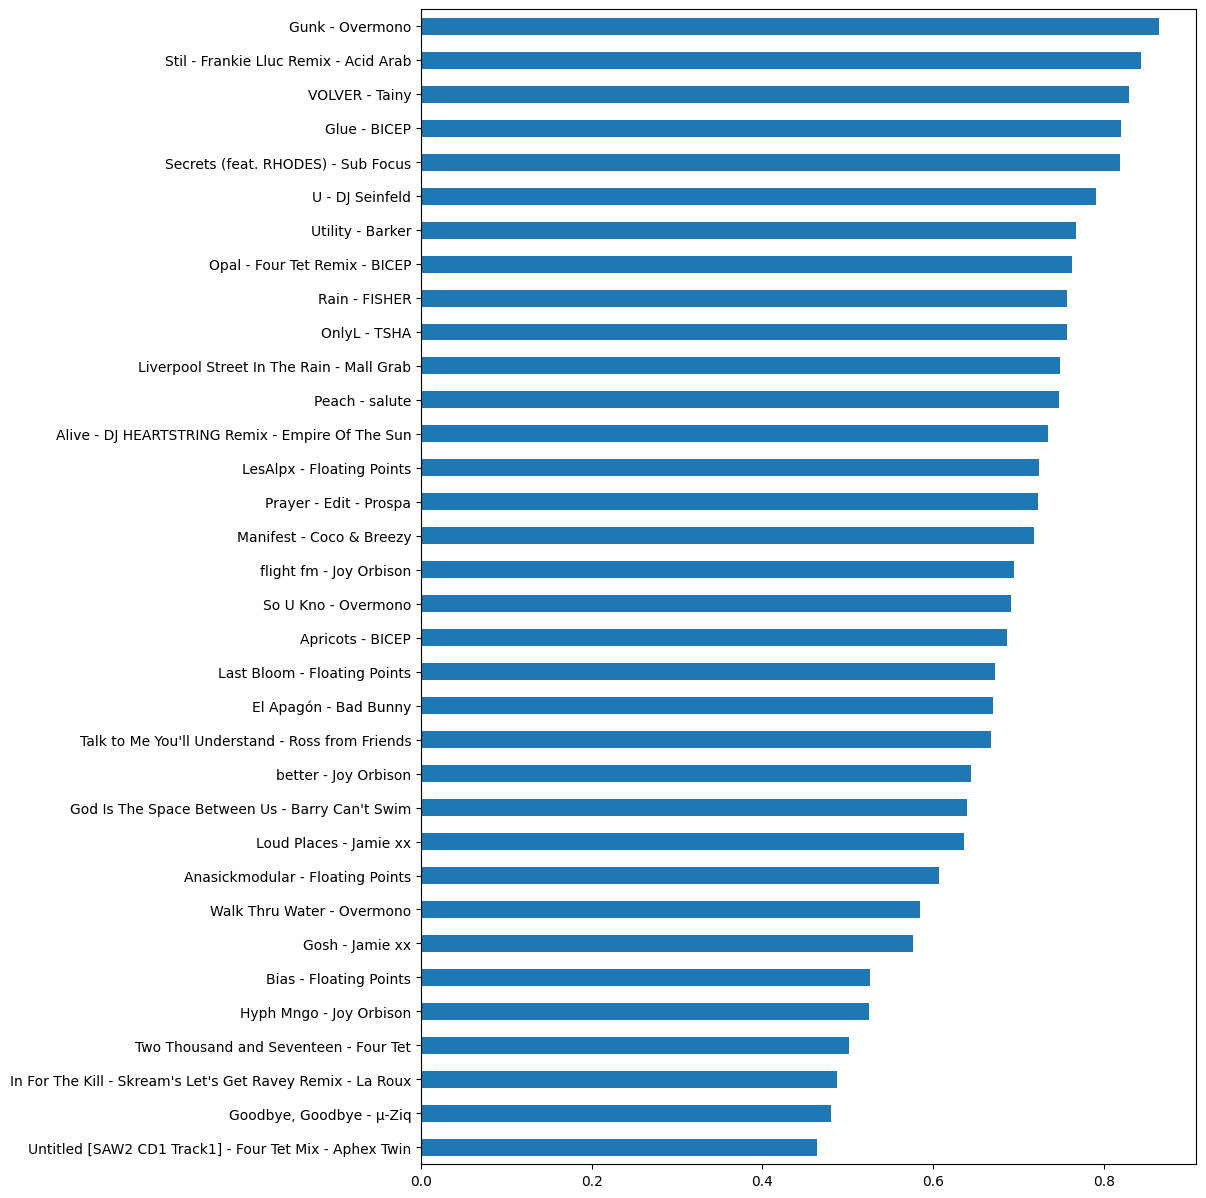

In [81]:
features['peak_score'].sort_values().plot(kind='barh', figsize=(10,15))

Overmono - Gunk would be our most energetic + danceable song - definetly a peak in the set!

Now it's time to create the set using the peak score we have created above. 

# Creating a set using the peak score

Now let's order the songs based on the peak score we just calculated. The idea is to replicate the arc of a real DJ set - starting low, gradually building to a peak, then easing back down toward the end. This is the structure I mentioned at the beginning, inspired by how a conductor curates an orchestral programme.

In [82]:
#sorting the peak score in ascending order for our set
features_sorted = features.sort_values('peak_score', ascending=True)

In [83]:
#i want the peak to be around 70% of the set 
peak_point = int(len(features_sorted) * 0.70)

In [84]:
build = features_sorted[:peak_point] #songs up to the peak point 
drop = features_sorted[peak_point:].sort_values('peak_score', ascending=False) #songs after the peak

In [85]:
set_sequence = pd.concat([build, drop]) 

In [86]:
set_sequence[['peak_score']]

,peak_score
Untitled [SAW2 CD1 Track1] - Four Tet Mix - Aphex Twin,0.4636
"Goodbye, Goodbye - µ-Ziq",0.4800
In For The Kill - Skream's Let's Get Ravey Remix - La Roux,0.4878
Two Thousand and Seventeen - Four Tet,0.5018
Hyph Mngo - Joy Orbison,0.5252
Bias - Floating Points,0.5260
Gosh - Jamie xx,0.5762
Walk Thru Water - Overmono,0.5844
Anasickmodular - Floating Points,0.6070
Loud Places - Jamie xx,0.6364


This is what our generated set looks like! There's a clear build up, peak, and drop off. 

In [87]:
#checking if of all the songs in the playlist are in the sequence
print(len(features))        
print(len(set_sequence))    

34
34


# Let's create a shorter set

For this next part I'm going to work with a smaller selection of tracks. In a real scenario a DJ might have hundreds of songs to choose from but only an hour or two to play. 

In this scenario the DJ has time to play 20 songs in total, and decided to have 13 songs in the build-up of the playlist and 7 songs in the drop. 

In [88]:
build_size = 13  # tracks in the build
drop_size = 7    # tracks in the drop

build = features_sorted[:build_size]
drop = features_sorted[build_size:build_size+drop_size].sort_values('peak_score', ascending=False)

set_sequence = pd.concat([build, drop])

This would be the new playlist based on the peak score!

In [89]:
set_sequence[['peak_score']]

,peak_score
Untitled [SAW2 CD1 Track1] - Four Tet Mix - Aphex Twin,0.4636
"Goodbye, Goodbye - µ-Ziq",0.4800
In For The Kill - Skream's Let's Get Ravey Remix - La Roux,0.4878
Two Thousand and Seventeen - Four Tet,0.5018
Hyph Mngo - Joy Orbison,0.5252
Bias - Floating Points,0.5260
Gosh - Jamie xx,0.5762
Walk Thru Water - Overmono,0.5844
Anasickmodular - Floating Points,0.6070
Loud Places - Jamie xx,0.6364


In [90]:
print(len(set_sequence))   

20


# Transitions 

Now that we have our set ordered by peak score, let's take a closer look at the transitions. This is where tempo comes back into the picture, even if the energy flow is good, a big BPM difference between two tracks can make a mix feel really off.
This is also where I think the project becomes most useful as a practical tool. Not just for generating a set order, but for showing which transitions are going to need the most work. A DJ can look at this and immediately know where to pay more attention when they're actually playing.

In [91]:
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import StandardScaler

In [92]:
scaled = StandardScaler().fit_transform(set_sequence[['peak_score']])
similarity_matrix = cosine_similarity(scaled)

Based on this new playlist, I wanted to identify any tracks that might clash when played back to back. To do this, I looked at two measures: the BPM difference and the peak score difference between consecutive songs.

In [93]:
set_sequence['bpm_diff'] = set_sequence['tempo'].diff().abs()
set_sequence['peak_diff'] = set_sequence['peak_score'].diff().abs()

set_sequence[['bpm_diff', 'peak_diff']].style.background_gradient(cmap='RdYlGn_r')

,bpm_diff,peak_diff
Untitled [SAW2 CD1 Track1] - Four Tet Mix - Aphex Twin,nan,nan
"Goodbye, Goodbye - µ-Ziq",53.083000,0.016400
In For The Kill - Skream's Let's Get Ravey Remix - La Roux,15.598000,0.007800
Two Thousand and Seventeen - Four Tet,69.985000,0.014000
Hyph Mngo - Joy Orbison,64.297000,0.023400
Bias - Floating Points,6.205000,0.000800
Gosh - Jamie xx,6.547000,0.050200
Walk Thru Water - Overmono,5.464000,0.008200
Anasickmodular - Floating Points,5.102000,0.022600
Loud Places - Jamie xx,30.070000,0.029400


Some tracks stand out as potentially problematic — particularly Goodbye, Goodbye by µ-Ziq, Two Thousand and Seventeen by Four Tet, and Hyph Mngo by Joy Orbison, all of which show large BPM jumps relative to their neighbours. Let's take a closer look at what BPMs those tracks actually have

In [94]:
set_sequence.loc['Goodbye, Goodbye - µ-Ziq', 'tempo']

129.882

In [95]:
set_sequence.loc['Two Thousand and Seventeen - Four Tet', 'tempo']

75.495

In [96]:
set_sequence.loc['In For The Kill - Skream\'s Let\'s Get Ravey Remix - La Roux', 'tempo']

145.48

In [97]:
set_sequence.loc['Untitled [SAW2 CD1 Track1] - Four Tet Mix - Aphex Twin', 'tempo']

76.799

I think my friend whose playlist I am using intended these tracks to be played at double the BPM, which is pretty common in DJ sets. But for this project, we're going to take the values as they are. Instead of dropping them from the playlist, I'll move the three outlier tracks to the beginning to act as an intro, letting the set slowly build from there.

In [98]:
slow_tempo = ['Untitled [SAW2 CD1 Track1] - Four Tet Mix - Aphex Twin', 
              'Two Thousand and Seventeen - Four Tet', 
              'Goodbye, Goodbye - µ-Ziq']

intro = set_sequence.loc[slow_tempo]
rest = set_sequence.drop(slow_tempo)

set_sequence = pd.concat([intro, rest])

In [99]:
set_sequence[['peak_score']]

,peak_score
Untitled [SAW2 CD1 Track1] - Four Tet Mix - Aphex Twin,0.4636
Two Thousand and Seventeen - Four Tet,0.5018
"Goodbye, Goodbye - µ-Ziq",0.4800
In For The Kill - Skream's Let's Get Ravey Remix - La Roux,0.4878
Hyph Mngo - Joy Orbison,0.5252
Bias - Floating Points,0.5260
Gosh - Jamie xx,0.5762
Walk Thru Water - Overmono,0.5844
Anasickmodular - Floating Points,0.6070
Loud Places - Jamie xx,0.6364


Let's reorder and have another look.

In [100]:
set_sequence['bpm_diff'] = set_sequence['tempo'].diff().abs()
set_sequence['peak_diff'] = set_sequence['peak_score'].diff().abs()

set_sequence[['bpm_diff', 'peak_diff']].style.background_gradient(cmap='RdYlGn_r')

,bpm_diff,peak_diff
Untitled [SAW2 CD1 Track1] - Four Tet Mix - Aphex Twin,nan,nan
Two Thousand and Seventeen - Four Tet,1.304000,0.038200
"Goodbye, Goodbye - µ-Ziq",54.387000,0.021800
In For The Kill - Skream's Let's Get Ravey Remix - La Roux,15.598000,0.007800
Hyph Mngo - Joy Orbison,5.688000,0.037400
Bias - Floating Points,6.205000,0.000800
Gosh - Jamie xx,6.547000,0.050200
Walk Thru Water - Overmono,5.464000,0.008200
Anasickmodular - Floating Points,5.102000,0.022600
Loud Places - Jamie xx,30.070000,0.029400


 Most transitions are looking a lot smoother, the majority of BPM jumps are under 10, which is pretty reasonable for mixing.
Goodbye, Goodbye by µ-Ziq is still a bit of a problem with a 54 BPM jump, and Loud Places by Jamie xx and the La Roux track also stand out a little. But overall this is already a much better starting point than before.
The peak_diff column is mostly green across the board, which is good, it means the energy is consistent between tracks. Prayer by Prospa and Gosh by Jamie xx are the two that spike a bit more, so those transitions might need a bit more care.

Now let's calculate how smooth each transition is. Since the peak_diff values are on a much smaller scale than the BPM ones, we'll multiply them by 100 first before combining the two.

In [101]:
set_sequence['transition_cost'] = (
    set_sequence['bpm_diff'] +
    set_sequence['peak_diff'] * 100)

In [102]:
set_sequence[['bpm_diff','peak_diff','transition_cost']]

,bpm_diff,peak_diff,transition_cost
Untitled [SAW2 CD1 Track1] - Four Tet Mix - Aphex Twin,NaN,NaN,NaN
Two Thousand and Seventeen - Four Tet,1.304,0.0382,5.124
"Goodbye, Goodbye - µ-Ziq",54.387,0.0218,56.567
In For The Kill - Skream's Let's Get Ravey Remix - La Roux,15.598,0.0078,16.378
Hyph Mngo - Joy Orbison,5.688,0.0374,9.428
Bias - Floating Points,6.205,0.0008,6.285
Gosh - Jamie xx,6.547,0.0502,11.567
Walk Thru Water - Overmono,5.464,0.0082,6.284
Anasickmodular - Floating Points,5.102,0.0226,7.362
Loud Places - Jamie xx,30.070,0.0294,33.010


Now let's visualise which transitions are the roughest, so we can see the problem areas at a glance.

Text(0, 0.5, 'Transition Cost')

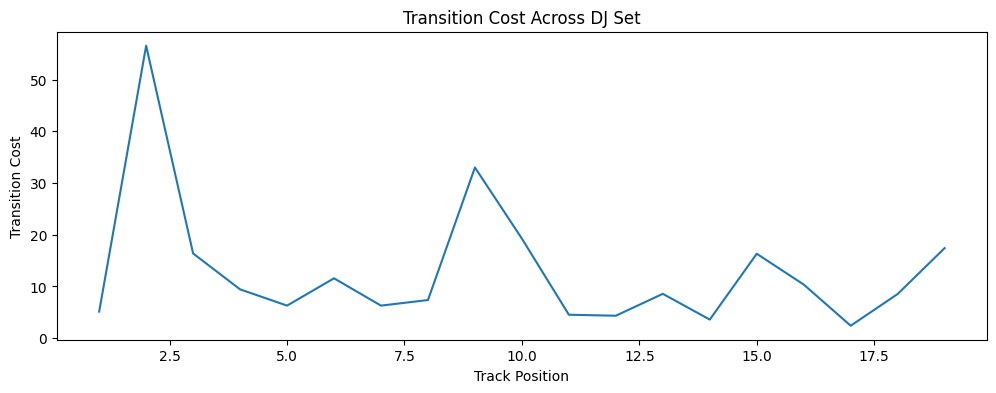

In [103]:
set_sequence['transition_cost'].reset_index(drop=True).plot(figsize=(12,4))

plt.title("Transition Cost Across DJ Set")
plt.xlabel("Track Position")
plt.ylabel("Transition Cost")

The transition cost plot gives a nice visual overview of how smoothly the set flows from track to track. Most transitions are in the 4–12 range, which means the tempo and energy are moving pretty consistently throughout. The big spike at position 2 (~56) is the low BPM transition we flagged earlier, that's the µ-Ziq track jumping into the rest of the set, which would need some real mixing skill to pull off smoothly. There's also a second smaller spike around position 9 (~33) that's worth keeping an eye on. Overall though, the set is looking fairly well-structured.

Now let's look at the energy distribution throughout the set as well!

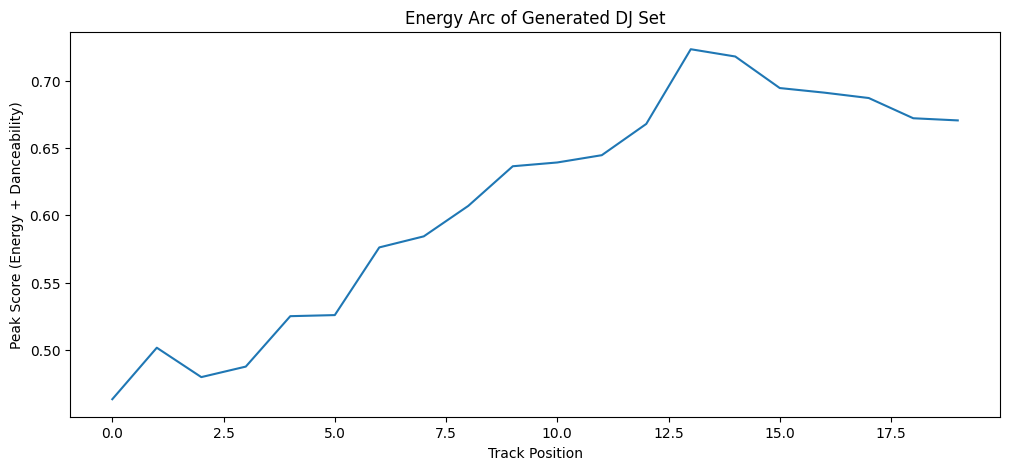

In [104]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

set_sequence['peak_score'].reset_index(drop=True).plot()

plt.title("Energy Arc of Generated DJ Set")
plt.xlabel("Track Position")
plt.ylabel("Peak Score (Energy + Danceability)")

plt.show()

This is looking pretty much exactly like what a good DJ set should look like. It starts low, builds steadily through the middle, hits a peak around track 13, and then gradually comes back down toward the end. Really happy with how this turned out!

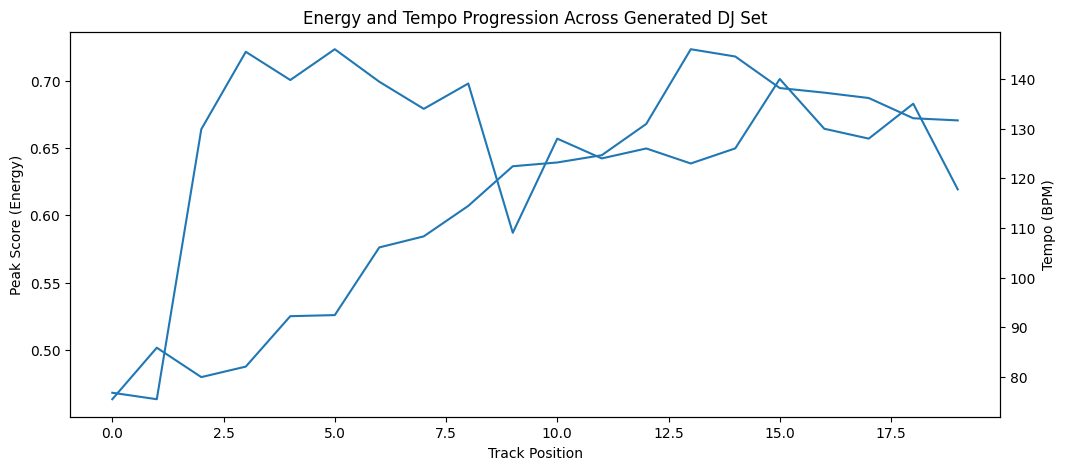

In [105]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(12,5))

# Energy arc
ax1.plot(set_sequence['peak_score'].reset_index(drop=True))
ax1.set_ylabel("Peak Score (Energy)")
ax1.set_xlabel("Track Position")
ax1.set_title("Energy and Tempo Progression Across Generated DJ Set")

# Tempo line
ax2 = ax1.twinx()
ax2.plot(set_sequence['tempo'].reset_index(drop=True))
ax2.set_ylabel("Tempo (BPM)")

plt.show()

This is actually looking pretty good! The set starts low on energy, which is exactly what you'd want, an intro before things pick up. It then builds nicely towards a peak around tracks 3 and 13, before gradually coming back down toward the end.
It's not a perfectly smooth curve, but that's fine, a real DJ set isn't meant to be completely linear. The dips and rises in the middle keep things interesting. What matters is the overall shape, and you can clearly see that build-up, peak, and wind-down arc that makes a good set.

# Conclusion and reflection

Overall, I'm pretty happy with how this turned out, I managed to do what I set out to do without any major issues. The only real headache was finding the right playlist to work with at the start.
I think this could be a genuinely useful tool for beginner DJs who aren't sure where to start when building a set, but also for more experienced ones. It can give a clear picture of which transitions are going to need the most attention when they're actually behind the decks.

If I had more time, I'd love to take this further with proper user testing across different DJs: different genres, different styles, different set lengths. Every DJ has their own logic and flow, so it would be really interesting to see how well this holds up across more varied playlists. That said, I did share the outputs with my friend who inspired the whole project, and she was really pleased with the results! She thought it could be genuinely useful, especially when building a set from scratch and trying to figure out the overall shape and structure. Which honestly is exactly what I set out to do, so that felt like a good sign.

That said, everything here should be taken with a grain of salt. At the end of the day, it's an algorithm deciding whether a song is more energetic or danceable than another, and that doesn't always reflect how a track actually feels when you're playing it to a crowd. The way I see this project is not as a definitive answer, but as a starting point, something to give a beginner DJ a direction rather than a finished set.

# LLM Disclaimer
An LLM was used throughout this project for proofreading, correcting grammar, and helping clean up written explanations in the notebook.
